# Exploratory Data Analysis — Olist Customers
**Tujuan:** memahami sebaran geografis basis pelanggan Olist, tingkat pembelian ulang (repeat), dan konsentrasi pasar,
sebagai dasar keputusan ekspansi wilayah, retensi, dan logistik.

**Cakupan data:** hanya `olist_customers_dataset.csv`. Tidak ada data transaksi, harga, produk, maupun tanggal —
sehingga revenue, AOV, dan analisis time series **tidak dapat** dilakukan.

**Konvensi:** setiap temuan ditandai **[FAKTA]** (dihitung dari data), **[ASUMSI]**, atau **[HIPOTESIS]** (perlu divalidasi).

> **[ASUMSI]** 1 `customer_id` = 1 pesanan (sesuai dokumentasi publik dataset Olist), sehingga jumlah `customer_id`
> per `customer_unique_id` dipakai sebagai *proksi* jumlah pesanan per pelanggan.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC, VIS = ROOT/'data'/'processed', ROOT/'visuals'
VIS.mkdir(exist_ok=True)

# Palet konsisten: 1 warna utama, 1 aksen untuk sorotan, abu-abu untuk konteks
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRAY,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.grid': True, 'grid.color': '#ecebe7',
    'grid.linewidth': .8, 'axes.axisbelow': True, 'font.size': 10})
def save(fig, name): fig.savefig(VIS/f'{name}.png'); plt.show()
pd.set_option('display.float_format', '{:,.2f}'.format)

df   = pd.read_csv(PROC/'customers_clean.csv', dtype={'customer_zip_code_prefix': str})
cust = pd.read_csv(PROC/'dim_customer.csv')
log  = pd.read_csv(PROC/'cleaning_log.csv')
print(df.shape, cust.shape)

(99441, 12) (96096, 11)


## 1. Data Understanding & kondisi before/after cleaning

In [2]:
display(log)
display(df.dtypes.to_frame('dtype').assign(n_unique=df.nunique(), missing=df.isna().sum()))
df.head()

,step,rows,cols,missing_cells,duplicate_rows,note
0,0_raw,99441,5,0,0,data mentah
1,1_missing_check,99441,5,0,0,0 missing value -> tidak ada imputasi
2,2_duplicates,99441,5,0,0,"duplikat baris=0, duplikat customer_id=0 -> ti..."
3,3_standardize,99441,5,0,0,"trim, zfill(5) kode pos, UPPER state, lower+ta..."
4,4_validate,99441,5,0,0,"state termasuk 27 UF, zip 5 digit, id 32-hex: ..."
5,5_city_consistency,99441,5,0,0,6 grup varian kota distandarkan
6,6_features,99441,11,0,0,"city_state_key, state_name, region, city_displ..."
7,7_outlier_flag,99441,12,0,0,19 pelanggan ditandai high-frequency (>=5 record)


,dtype,n_unique,missing
customer_id,object,99441,0
customer_unique_id,object,96096,0
customer_zip_code_prefix,object,14994,0
customer_city,object,4113,0
city_display,object,4113,0
customer_state,object,27,0
state_name,object,27,0
region,object,5,0
city_state_key,object,4304,0
records_per_customer,int64,9,0


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,city_display,customer_state,state_name,region,city_state_key,records_per_customer,is_repeat_customer,is_high_frequency
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,Franca,SP,São Paulo,Sudeste,franca - SP,1,False,False
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,Sao Bernardo do Campo,SP,São Paulo,Sudeste,sao bernardo do campo - SP,1,False,False
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,Sao Paulo,SP,São Paulo,Sudeste,sao paulo - SP,1,False,False
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,Mogi das Cruzes,SP,São Paulo,Sudeste,mogi das cruzes - SP,1,False,False
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,Campinas,SP,São Paulo,Sudeste,campinas - SP,1,False,False


## 2. Univariate Analysis
### 2.1 Distribusi pelanggan per negara bagian (state)

,customers,share_%,cum_%
primary_state,,,
SP,40291,41.93,41.93
RJ,12380,12.88,54.81
MG,11252,11.71,66.52
RS,5276,5.49,72.01
PR,4880,5.08,77.09
SC,3532,3.68,80.76
BA,3275,3.41,84.17
DF,2075,2.16,86.33
ES,1963,2.04,88.37


Statistik customers per state:
count       27.00
mean     3,559.10
std      7,981.20
min         45.00
25%        370.50
50%        874.00
75%      2,675.00
max     40,291.00
Name: customers, dtype: float64
skewness: 4.1


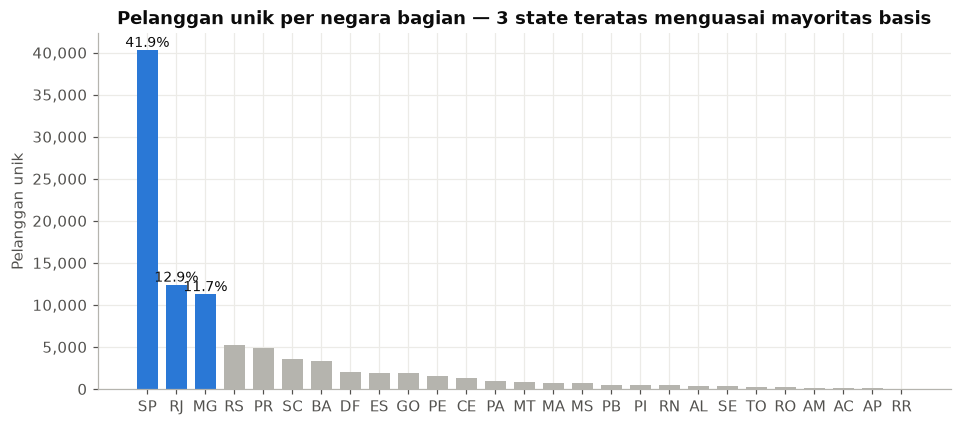

In [3]:
TOTAL_REC, TOTAL_CUST = len(df), cust.shape[0]
st = (cust.groupby('primary_state').size().sort_values(ascending=False).rename('customers').to_frame())
st['share_%'] = st.customers / TOTAL_CUST * 100
st['cum_%'] = st['share_%'].cumsum()
display(st.head(10))
print('Statistik customers per state:'); print(st.customers.describe().round(1)); print('skewness:', round(st.customers.skew(), 2))

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [BLUE if i < 3 else GRAY for i in range(len(st))]
ax.bar(st.index, st.customers, color=colors, width=.72)
for i, (s, r) in enumerate(st.head(3).iterrows()):
    ax.text(i, r.customers, f"{r['share_%']:.1f}%", ha='center', va='bottom', fontsize=9, color=INK)
ax.set_title('Pelanggan unik per negara bagian — 3 state teratas menguasai mayoritas basis')
ax.set_ylabel('Pelanggan unik'); ax.yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
save(fig, '01_customers_by_state')

### 2.2 Distribusi per makro-region (enrichment IBGE)

,customers,share_%
primary_region,,
Sudeste,65886,68.56
Sul,13688,14.24
Nordeste,9135,9.51
Centro-Oeste,5594,5.82
Norte,1793,1.87


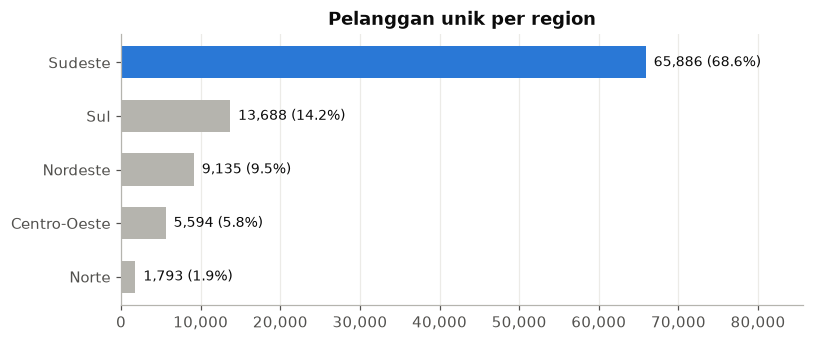

In [4]:
rg = cust.groupby('primary_region').size().sort_values().rename('customers').to_frame()
rg['share_%'] = rg.customers / TOTAL_CUST * 100
display(rg.sort_values('customers', ascending=False))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(rg.index, rg.customers, color=[BLUE if r=='Sudeste' else GRAY for r in rg.index], height=.6)
for y, (r, v) in enumerate(rg.iterrows()):
    ax.text(v.customers, y, f"  {v.customers:,.0f} ({v['share_%']:.1f}%)", va='center', fontsize=9)
ax.set_title('Pelanggan unik per region'); ax.set_xlim(0, rg.customers.max()*1.3); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
save(fig, '02_customers_by_region')

### 2.3 Distribusi kota — konsentrasi & long tail

count    4,304.00
mean        22.36
std        263.44
min          1.00
25%          1.00
50%          3.00
75%          8.00
max     14,984.00
Name: customers, dtype: float64
mode: 1 | skewness: 46.79
kota dengan hanya 1 pelanggan: 1290 (30.0% dari kota)
Outlier IQR (> 18 pelanggan): 542 kota


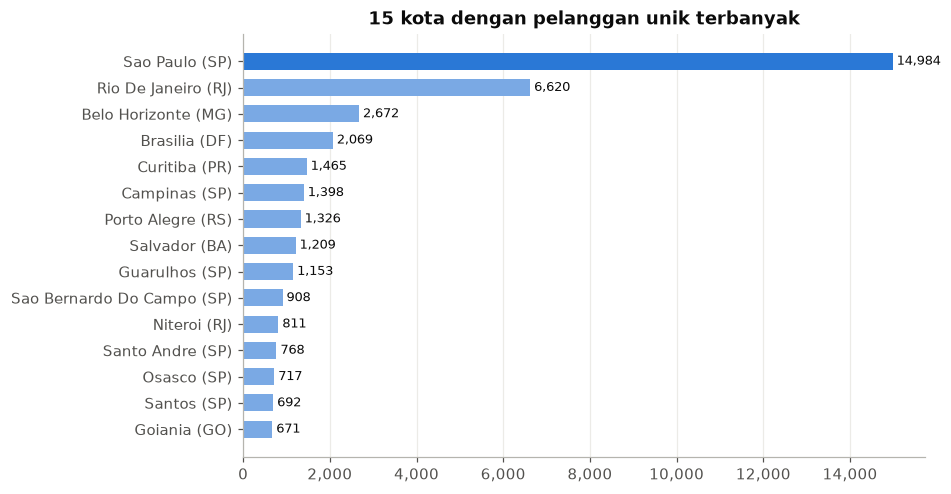

In [5]:
city = df.groupby('city_state_key').customer_unique_id.nunique().sort_values(ascending=False).rename('customers')
print(city.describe().round(2)); print('mode:', city.mode()[0], '| skewness:', round(city.skew(), 2))
print('kota dengan hanya 1 pelanggan:', (city == 1).sum(), f'({(city==1).mean()*100:.1f}% dari kota)')
q1, q3 = city.quantile([.25, .75]); upper = q3 + 1.5*(q3-q1)
print(f'Outlier IQR (> {upper:.0f} pelanggan): {(city>upper).sum()} kota')
top = city.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([k.split(' - ')[0].title()+' ('+k.split(' - ')[1]+')' for k in top.index], top.values,
        color=[BLUE if v == top.max() else '#7aa9e4' for v in top.values], height=.65)
for y, v in enumerate(top.values): ax.text(v, y, f' {v:,}', va='center', fontsize=8.5)
ax.set_title('15 kota dengan pelanggan unik terbanyak'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
save(fig, '03_top_cities')

41 kota (1.0%) -> 50% pelanggan; 359 kota (8.3%) -> 80% pelanggan
Gini kota = 0.861 | HHI state = 2,164 (>2.500 = sangat terkonsentrasi)


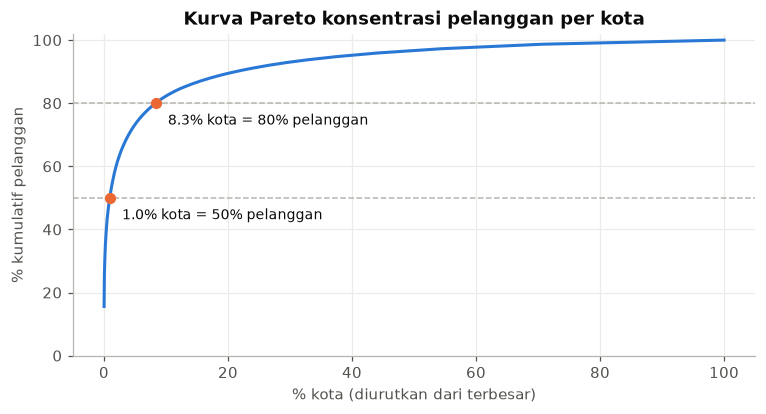

In [6]:
# Pareto: berapa persen kota yang menyumbang 50% / 80% pelanggan?
cum = city.cumsum() / city.sum() * 100
n50, n80 = (cum < 50).sum() + 1, (cum < 80).sum() + 1
print(f'{n50} kota ({n50/len(city)*100:.1f}%) -> 50% pelanggan; {n80} kota ({n80/len(city)*100:.1f}%) -> 80% pelanggan')
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return (2*np.arange(1, n+1) - n - 1).dot(x) / (n * x.sum())
hhi_state = ((st.customers / TOTAL_CUST * 100) ** 2).sum()
print(f'Gini kota = {gini(city):.3f} | HHI state = {hhi_state:,.0f} (>2.500 = sangat terkonsentrasi)')
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, len(city)+1) / len(city) * 100
ax.plot(x, cum.values, color=BLUE, lw=2)
for p, n in [(50, n50), (80, n80)]:
    ax.axhline(p, color=GRAY, lw=1, ls='--'); ax.scatter([n/len(city)*100], [p], color=ORANGE, s=40, zorder=3)
    ax.annotate(f'{n/len(city)*100:.1f}% kota = {p}% pelanggan', (n/len(city)*100, p), xytext=(8, -14), textcoords='offset points', fontsize=9)
ax.set_xlabel('% kota (diurutkan dari terbesar)'); ax.set_ylabel('% kumulatif pelanggan'); ax.set_ylim(0, 102)
ax.set_title('Kurva Pareto konsentrasi pelanggan per kota')
save(fig, '04_pareto_cities')

### 2.4 Jumlah pesanan (proksi) per pelanggan

mean=1.0348 median=1 mode=1 std=0.2144 min=1 max=17 skew=11.86


,customers,share_%
segment,,
1. One-time,93099,96.88
2. Repeat (2x),2745,2.86
3. Loyal (3x+),252,0.26


,customers
records,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


Outlier (>=5 record): 19 pelanggan; maksimum 17 record -> ditandai, tidak dihapus


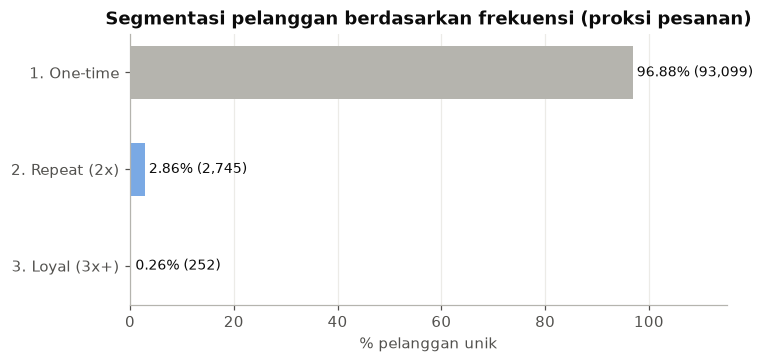

In [7]:
r = cust.records
print(f"mean={r.mean():.4f} median={r.median():.0f} mode={r.mode()[0]} std={r.std():.4f} min={r.min()} max={r.max()} skew={r.skew():.2f}")
seg = cust.segment.value_counts().sort_index().to_frame('customers'); seg['share_%'] = seg.customers/TOTAL_CUST*100
display(seg)
display(r.value_counts().sort_index().to_frame('customers'))
print('Outlier (>=5 record):', (r >= 5).sum(), 'pelanggan; maksimum', r.max(), 'record -> ditandai, tidak dihapus')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(seg.index[::-1], seg['share_%'][::-1], color=[BLUE, '#7aa9e4', GRAY], height=.55)
for y, (s, v) in enumerate(seg[::-1].iterrows()): ax.text(v['share_%'], y, f" {v['share_%']:.2f}% ({int(v.customers):,})", va='center', fontsize=9)
ax.set_xlim(0, 115); ax.set_xlabel('% pelanggan unik'); ax.grid(axis='y', visible=False)
ax.set_title('Segmentasi pelanggan berdasarkan frekuensi (proksi pesanan)')
save(fig, '05_customer_segments')

## 3. Bivariate Analysis
### 3.1 Repeat rate per region — apakah berbeda signifikan?

In [8]:
rr_reg = cust.groupby('primary_region').agg(customers=('customer_unique_id','count'), repeat=('is_repeat_customer','sum'))
rr_reg['repeat_rate_%'] = rr_reg.repeat / rr_reg.customers * 100
display(rr_reg.sort_values('repeat_rate_%', ascending=False))
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(cust.primary_region, cust.is_repeat_customer))
print(f'Chi-square region x repeat: chi2={chi2:.2f}, dof={dof}, p-value={p:.4f}')
print('Overall repeat rate:', round(cust.is_repeat_customer.mean()*100, 2), '%')

,customers,repeat,repeat_rate_%
primary_region,,,
Sudeste,65886,2125,3.23
Centro-Oeste,5594,178,3.18
Sul,13688,414,3.02
Norte,1793,50,2.79
Nordeste,9135,230,2.52


Chi-square region x repeat: chi2=14.52, dof=4, p-value=0.0058
Overall repeat rate: 3.12 %


### 3.2 Repeat rate per state vs ukuran pasar

,customers,repeat,avg_records,repeat_rate_%,ci_low_%,ci_high_%
primary_state,,,,,,
AC,77,4,1.05,5.19,2.04,12.61
RO,239,10,1.05,4.18,2.29,7.53
RJ,12380,425,1.04,3.43,3.13,3.77
GO,1951,65,1.04,3.33,2.62,4.22
MT,874,29,1.04,3.32,2.32,4.72
SP,40291,1302,1.04,3.23,3.06,3.41
RS,5276,168,1.04,3.18,2.74,3.69
DF,2075,65,1.03,3.13,2.47,3.97
MG,11252,341,1.03,3.03,2.73,3.36


Spearman (ukuran pasar state vs repeat rate): rho=0.385, p=0.0476


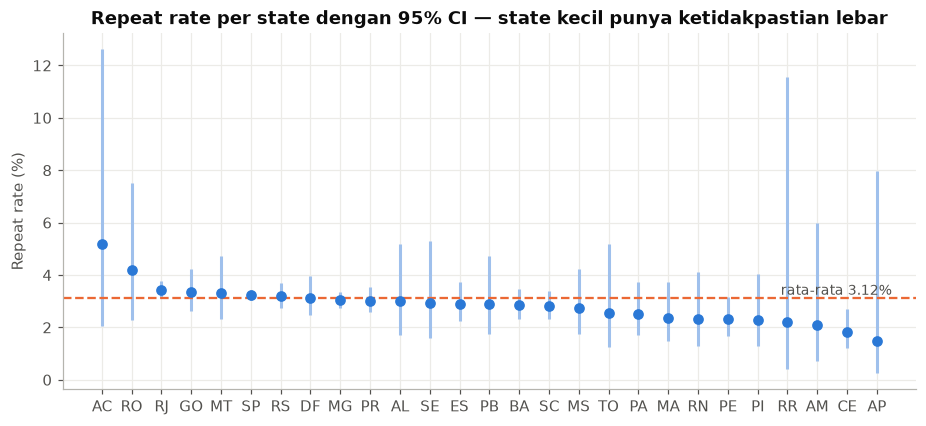

In [9]:
rr = cust.groupby('primary_state').agg(customers=('customer_unique_id','count'), repeat=('is_repeat_customer','sum'),
                                       avg_records=('records','mean'))
rr['repeat_rate_%'] = rr.repeat / rr.customers * 100
# Wilson 95% CI agar state kecil tidak disalahartikan
z = 1.96; n = rr.customers; ph = rr.repeat / n
den = 1 + z**2/n; centre = (ph + z**2/(2*n)) / den; half = z*np.sqrt(ph*(1-ph)/n + z**2/(4*n**2)) / den
rr['ci_low_%'], rr['ci_high_%'] = (centre-half)*100, (centre+half)*100
rr = rr.sort_values('repeat_rate_%', ascending=False)
display(rr)
rho, p_rho = stats.spearmanr(rr.customers, rr['repeat_rate_%'])
print(f'Spearman (ukuran pasar state vs repeat rate): rho={rho:.3f}, p={p_rho:.4f}')
overall = cust.is_repeat_customer.mean()*100
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.errorbar(rr.index, rr['repeat_rate_%'], yerr=[rr['repeat_rate_%']-rr['ci_low_%'], rr['ci_high_%']-rr['repeat_rate_%']],
            fmt='o', color=BLUE, ecolor='#9fc0ec', elinewidth=2, capsize=0, ms=6)
ax.axhline(overall, color=ORANGE, lw=1.5, ls='--'); ax.text(len(rr)-.5, overall, f' rata-rata {overall:.2f}%', color=INK2, va='bottom', ha='right', fontsize=9)
ax.set_ylabel('Repeat rate (%)'); ax.set_title('Repeat rate per state dengan 95% CI — state kecil punya ketidakpastian lebar')
save(fig, '06_repeat_rate_by_state')

### 3.3 Ukuran kota (tier) vs repeat rate

In [10]:
city_size = cust.groupby('primary_city_state_key').customer_unique_id.transform('count')
cust['city_tier'] = pd.cut(city_size, [0, 10, 100, 1000, np.inf],
                           labels=['Kecil (1-10)', 'Menengah (11-100)', 'Besar (101-1.000)', 'Metro (>1.000)'])
tier = cust.groupby('city_tier', observed=True).agg(cities=('primary_city_state_key','nunique'),
        customers=('customer_unique_id','count'), repeat_rate=('is_repeat_customer','mean'))
tier['repeat_rate'] *= 100; tier['share_customers_%'] = tier.customers/TOTAL_CUST*100
display(tier)
chi2t, pt, *_ = stats.chi2_contingency(pd.crosstab(cust.city_tier, cust.is_repeat_customer))
print(f'Chi-square city tier x repeat: chi2={chi2t:.2f}, p={pt:.4f}')

,cities,customers,repeat_rate,share_customers_%
city_tier,,,,
Kecil (1-10),3452,10215,2.75,10.63
Menengah (11-100),721,22232,3.14,23.14
Besar (101-1.000),122,30786,2.95,32.04
Metro (>1.000),9,32863,3.37,34.20


Chi-square city tier x repeat: chi2=14.54, p=0.0023


## 4. Multivariate Analysis — Region x Tier kota x Repeat rate

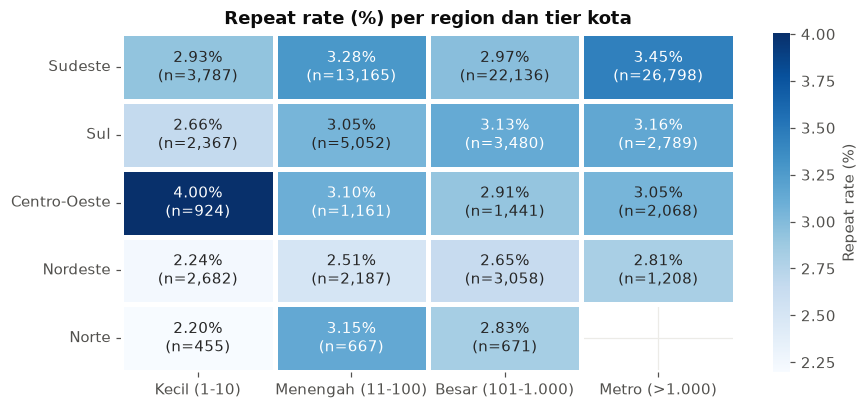

In [11]:
pv_rate = cust.pivot_table(index='primary_region', columns='city_tier', values='is_repeat_customer', aggfunc='mean', observed=True)*100
pv_n = cust.pivot_table(index='primary_region', columns='city_tier', values='customer_unique_id', aggfunc='count', observed=True)
order = ['Sudeste','Sul','Centro-Oeste','Nordeste','Norte']
pv_rate, pv_n = pv_rate.reindex(order), pv_n.reindex(order)
annot = pv_rate.map('{:.2f}'.format) + '%\n(n=' + pv_n.fillna(0).astype(int).map('{:,}'.format) + ')'
annot = annot.where(pv_n.notna(), '-')
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(pv_rate, annot=annot, fmt='', cmap='Blues', cbar_kws={'label': 'Repeat rate (%)'}, linewidths=2, linecolor='white', ax=ax)
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title('Repeat rate (%) per region dan tier kota')
save(fig, '07_heatmap_region_tier')

,customers,cities,cust_per_city,repeat_rate_%
primary_state,,,,
SP,40291,625,64.47,3.23
RJ,12380,149,83.09,3.43
MG,11252,745,15.10,3.03
RS,5276,379,13.92,3.18
PR,4880,364,13.41,3.01
SC,3532,240,14.72,2.80
BA,3275,351,9.33,2.84
DF,2075,6,345.83,3.13
ES,1963,95,20.66,2.90


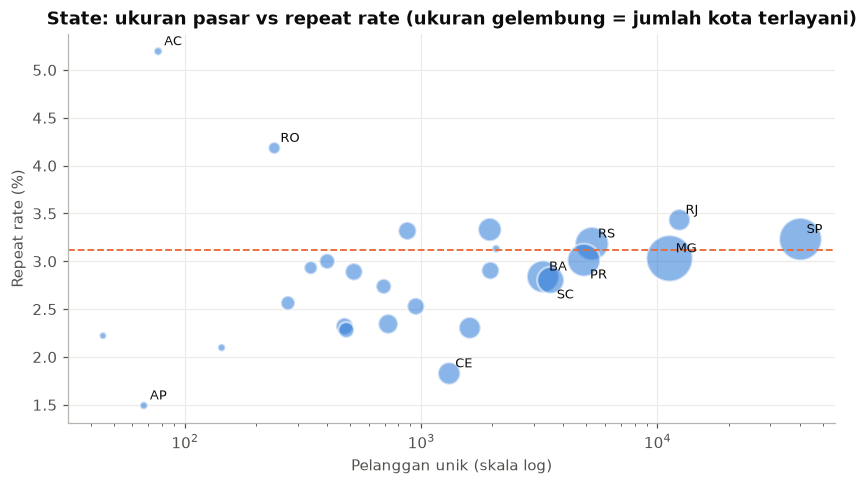

In [12]:
# Bubble: per state — volume pelanggan (x), repeat rate (y), jumlah kota terlayani (ukuran)
cities_served = cust.groupby('primary_state').primary_city_state_key.nunique()
b = rr.join(cities_served.rename('cities'))
b['cust_per_city'] = b.customers / b.cities
display(b[['customers','cities','cust_per_city','repeat_rate_%']].sort_values('customers', ascending=False))
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(b.customers, b['repeat_rate_%'], s=b.cities/b.cities.max()*900+20, color=BLUE, alpha=.55, edgecolor='white', lw=1.5)
for s, r_ in b.iterrows():
    if r_.customers > 3000 or r_['repeat_rate_%'] > 4 or r_['repeat_rate_%'] < 2:
        ax.annotate(s, (r_.customers, r_['repeat_rate_%']), xytext=(4, -12 if s in ('SC','PR') else 4), textcoords='offset points', fontsize=8.5)
ax.set_xscale('log'); ax.set_xlabel('Pelanggan unik (skala log)'); ax.set_ylabel('Repeat rate (%)')
ax.axhline(overall, color=ORANGE, lw=1.2, ls='--')
ax.set_title('State: ukuran pasar vs repeat rate (ukuran gelembung = jumlah kota terlayani)')
save(fig, '08_bubble_state')

## 5. Analisis tambahan — mobilitas pelanggan

In [13]:
mv = cust[cust.is_repeat_customer]
print('Pelanggan repeat:', len(mv))
print('  ...dengan >1 kode pos  :', mv.moved_location.sum(), f'({mv.moved_location.mean()*100:.1f}%)')
print('  ...dengan >1 kota      :', (mv.distinct_cities > 1).sum())
print('  ...dengan >1 state     :', (mv.distinct_states > 1).sum())

Pelanggan repeat: 2997
  ...dengan >1 kode pos  : 250 (8.3%)
  ...dengan >1 kota      : 122
  ...dengan >1 state     : 39


## 6. KPI Summary (dihitung dari data aktual)

In [14]:
kpi = pd.DataFrame([
    ('Total Customer Records (proksi pesanan)', TOTAL_REC),
    ('Unique Customers', TOTAL_CUST),
    ('Repeat Customers', int(cust.is_repeat_customer.sum())),
    ('Repeat Customer Rate (%)', cust.is_repeat_customer.mean()*100),
    ('One-time Customer Rate (%)', (1-cust.is_repeat_customer.mean())*100),
    ('Avg Records per Customer', cust.records.mean()),
    ('States Covered', df.customer_state.nunique()),
    ('Cities Covered (city-state)', df.city_state_key.nunique()),
    ('ZIP Prefixes Covered', df.customer_zip_code_prefix.nunique()),
    ('Top-3 State Share (%)', st['share_%'].head(3).sum()),
    ('Top-5 State Share (%)', st['share_%'].head(5).sum()),
    ('Top-10 City Share (%)', city.head(10).sum()/city.sum()*100),
    ('HHI State', hhi_state),
    ('Gini Kota', gini(city)),
    ('% Kota untuk 80% Pelanggan', n80/len(city)*100),
    ('Kota dengan 1 Pelanggan', int((city==1).sum())),
], columns=['KPI', 'Value'])
kpi.to_csv(PROC/'kpi_summary.csv', index=False)
rr.to_csv(PROC/'state_summary.csv'); tier.to_csv(PROC/'tier_summary.csv')
kpi

,KPI,Value
0,Total Customer Records (proksi pesanan),"99,441.00"
1,Unique Customers,"96,096.00"
2,Repeat Customers,"2,997.00"
3,Repeat Customer Rate (%),3.12
4,One-time Customer Rate (%),96.88
5,Avg Records per Customer,1.03
6,States Covered,27.00
7,Cities Covered (city-state),"4,304.00"
8,ZIP Prefixes Covered,"14,994.00"
9,Top-3 State Share (%),66.52


## 7. Ringkasan temuan EDA
Lihat `reports/business_analysis_report.md` untuk interpretasi bisnis lengkap (apa yang terjadi, pola, kemungkinan
penyebab, dampak, rekomendasi). Seluruh angka di laporan bersumber dari output notebook ini.
Korelasi/asosiasi di atas **bukan** bukti sebab-akibat.